# What a small job-posting sample can tell me

This is a case study of records collected from 26 May to 10 June 2026, not a current list of jobs. I wanted to understand the mix of roles in my feed. Before using the counts to guide a search, I need to check what the data can actually support.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Markdown, Image
ROOT = next(p for p in (Path.cwd(), Path.cwd().parent) if (p / 'data/jobs_snapshot.csv').exists())
sys.path.insert(0, str(ROOT))
from src.analyse import run
m = run(ROOT / 'data/jobs_snapshot.csv', ROOT / 'reports/generated', ROOT / 'figures')
df = pd.read_csv(ROOT / 'data/jobs_snapshot.csv')
display(df.head(3))

,id,source,title,company,location,workplace_type,score,status,first_seen,posted
0,1,indeed,Junior Machine Learning Engineer,Information Tech Consultants,Greater London,On-site,88,new,2026-05-26 18:14:23,NaN
1,2,indeed,Junior Data Scientist,Information Tech Consultants,London,On-site,85,new,2026-05-26 18:14:23,NaN
2,3,indeed,AI / ML Engineer,Forge Holiday Group Ltd,Chester,Hybrid,72,new,2026-05-26 18:14:23,NaN


## Start with the quality checks

A unique internal ID does not prove a unique vacancy. Repeated titles at the same company and location might be reposts, collection duplicates or separate openings. I keep every source row and export the groups for review.

The snapshot contains **519 rows**. Posting dates are missing for **441 (84.97%)**. There are **105 repeated composite-key groups**, with **126 rows beyond the first**. These are candidates for investigation, not confirmed duplicate vacancies.

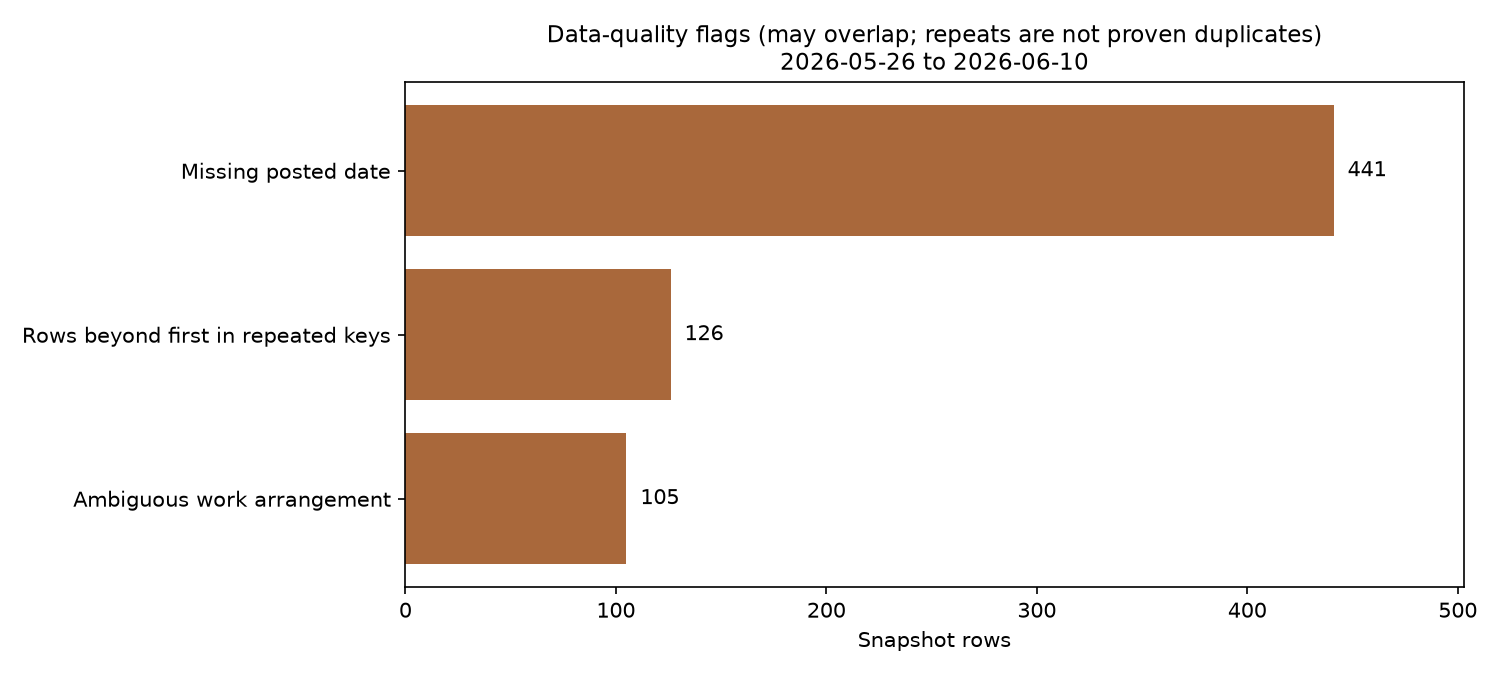

In [2]:
display(Markdown(f"The snapshot contains **{m['row_count']} rows**. Posting dates are missing for **{m['missing_posted_rows']} ({m['missing_posted_percent']}%)**. There are **{m['potential_repeated_groups']} repeated composite-key groups**, with **{m['rows_beyond_first_in_potential_groups']} rows beyond the first**. These are candidates for investigation, not confirmed duplicate vacancies."))
display(Image(filename=str(ROOT / 'figures/quality.png')))

## Which titles appear in the feed?

The labels below come from documented title rules. They do not check the full advert or establish seniority, required experience or work rights. The tests cover examples and edge cases; they are not an independent accuracy study.

Other                 142
Data Analyst          119
ML/AI Engineer         86
Software/Other Eng     80
Data Scientist         69
Data Engineer          23
Name: Snapshot rows, dtype: int64

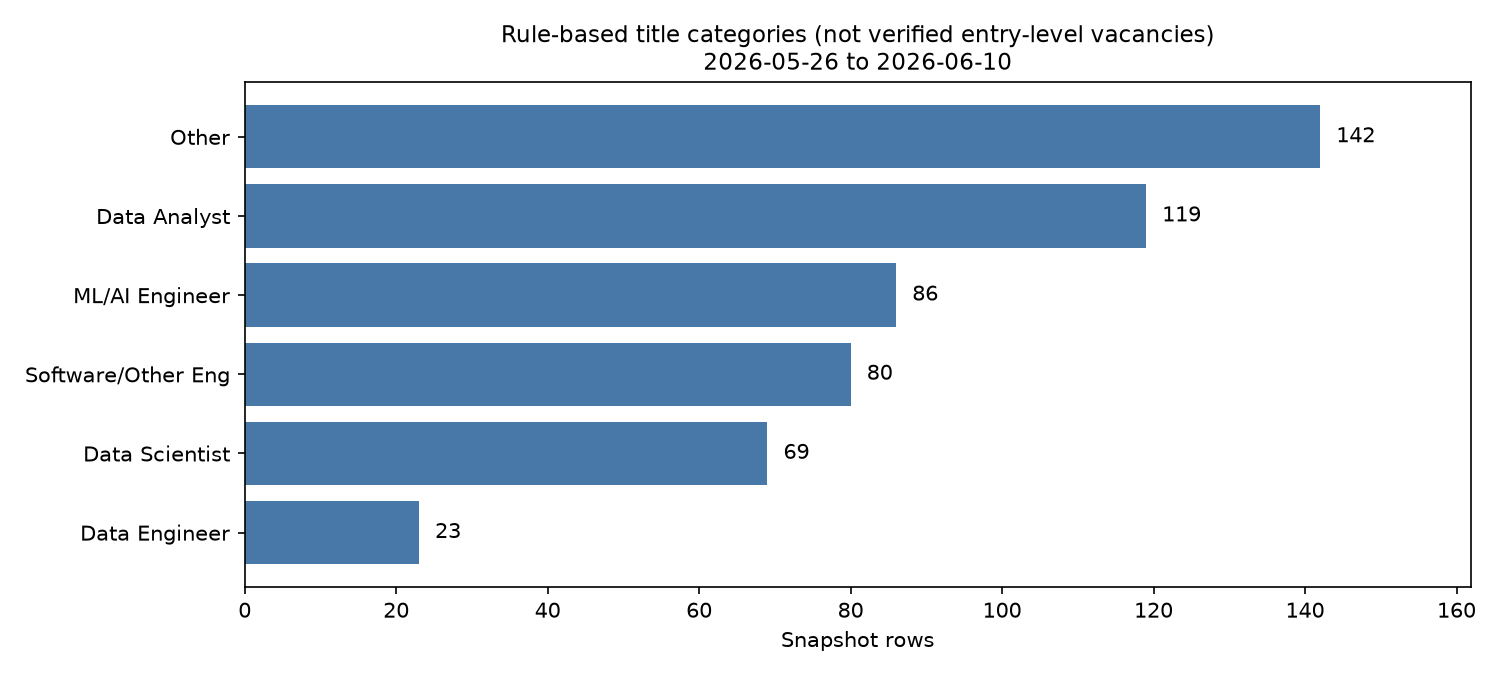

The Other category contains **142 rows**. Under a first-record-per-composite-key sensitivity scenario, **393 rows** remain. This scenario tests how counts might change; it is not a verified deduplication.

In [3]:
display(pd.Series(m['lane_counts'], name='Snapshot rows').sort_values(ascending=False))
display(Image(filename=str(ROOT / 'figures/lanes.png')))
display(Markdown(f"The Other category contains **{m['lane_counts'].get('Other', 0)} rows**. Under a first-record-per-composite-key sensitivity scenario, **{m['repeat_key_sensitivity']['representative_rows']} rows** remain. This scenario tests how counts might change; it is not a verified deduplication."))

## Work arrangements and location

The original workplace field mixes arrangements with labels such as Part-Time and Temporary. Mixed hybrid/on-site descriptions stay separate. A hybrid label does not say whether I can manage the office attendance, and a remote label does not establish UK eligibility.

Explicit hybrid or remote labels account for **113 rows (21.77%)**. Another **105 rows** have mixed arrangements. Counting the mixed labels as flexible would raise the share to **42.0%**, so the definition matters.

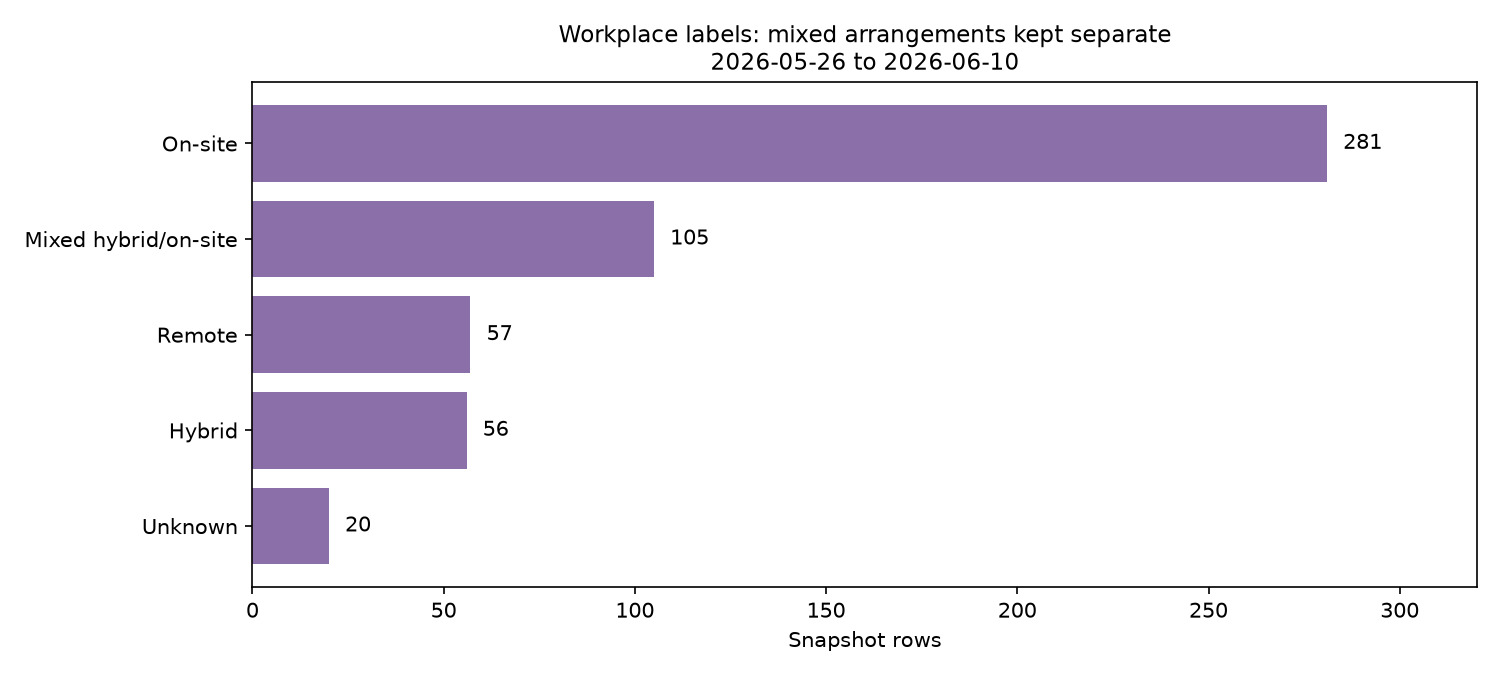

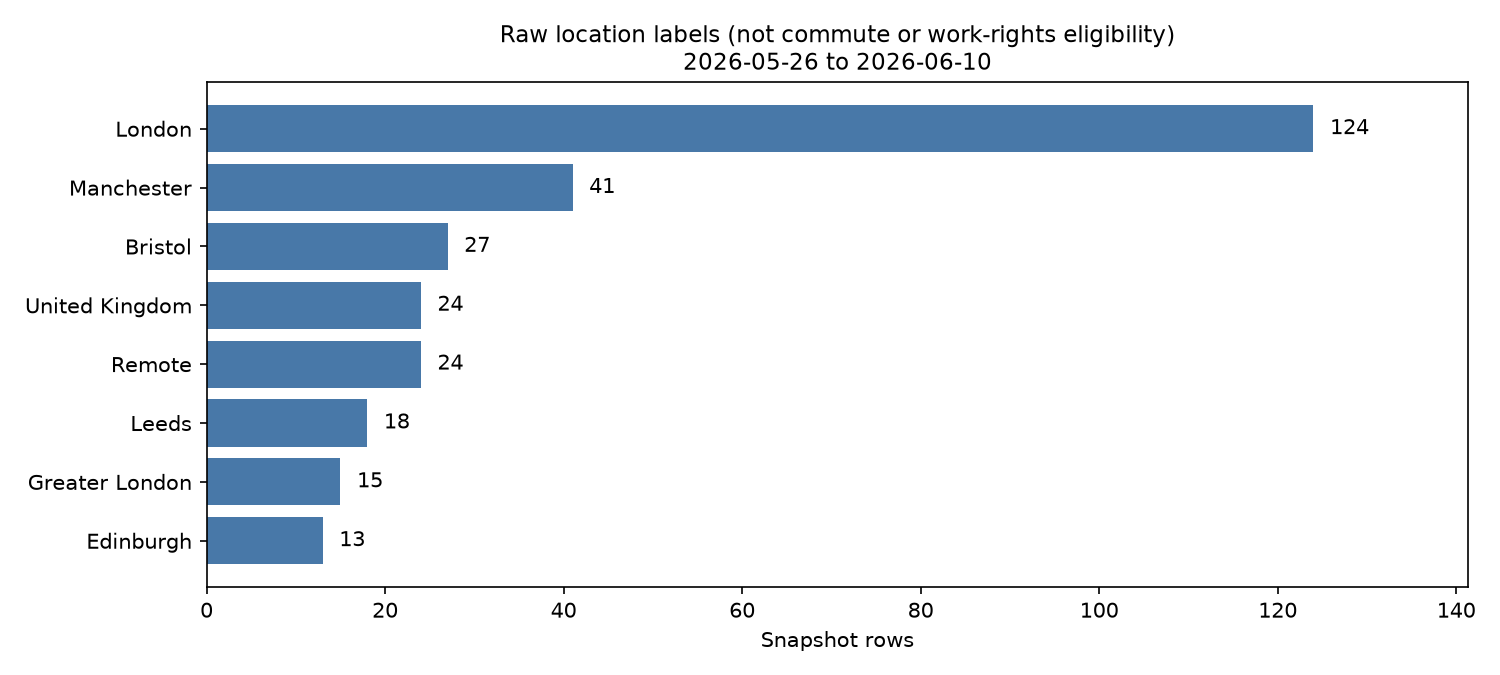

In [4]:
display(Markdown(f"Explicit hybrid or remote labels account for **{m['explicit_hybrid_remote_rows']} rows ({m['explicit_hybrid_remote_percent']}%)**. Another **{m['ambiguous_arrangement_rows']} rows** have mixed arrangements. Counting the mixed labels as flexible would raise the share to **{m['broad_flexible_including_mixed_percent']}%**, so the definition matters."))
display(Image(filename=str(ROOT / 'figures/geo_workplace.png')))
display(Image(filename=str(ROOT / 'figures/locations.png')))

## What do the old model scores mean?

These scores came from a private LLM step comparing adverts with my CV. The public snapshot does not retain the model, prompt, CV version or requirement evidence. I can describe the scores, but cannot calibrate them against hiring outcomes. A score of 70 is an analysis threshold, not a 70% interview chance.

60    252
70    121
80     36
Name: Rows meeting threshold, dtype: int64

Data Analyst          60.92
Data Engineer         51.35
Data Scientist        64.57
ML/AI Engineer        61.10
Other                 41.92
Software/Other Eng    50.75
Name: Mean historical score, dtype: float64

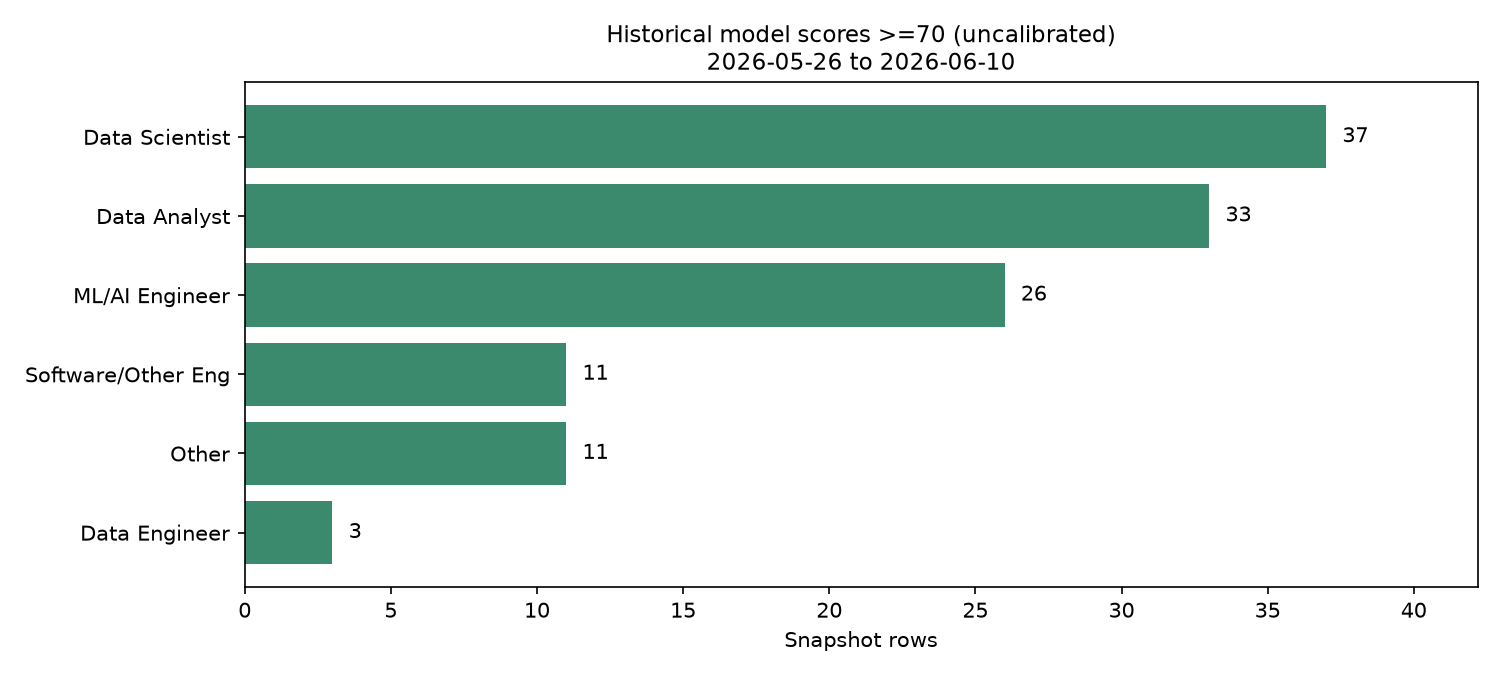

In [5]:
display(pd.Series(m['score_threshold_counts'], name='Rows meeting threshold'))
display(pd.Series(m['score_means_by_lane'], name='Mean historical score'))
display(Image(filename=str(ROOT / 'figures/high_fit_lanes.png')))

## Collection cadence

This chart measures when the pipeline first saw a row. It does not measure when an employer posted a vacancy. A large batch or a collection gap could reflect the collector rather than changes in demand.

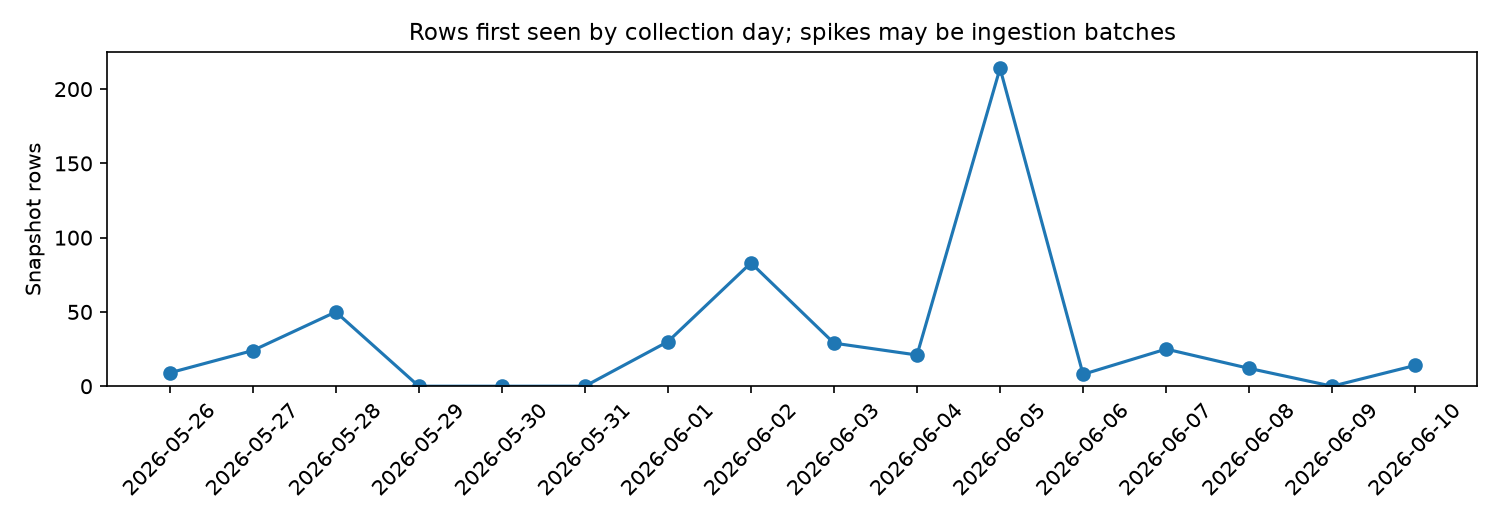

Rows were collected on **12 of 16 calendar days**. Source counts: **{'indeed': 495, 'linkedin': 24}**. The source mix and missing dates limit market-wide or freshness claims.

In [6]:
display(Image(filename=str(ROOT / 'figures/cadence.png')))
display(Markdown(f"Rows were collected on **{m['days_with_ingestion']} of {m['calendar_days']} calendar days**. Source counts: **{m['source_counts']}**. The source mix and missing dates limit market-wide or freshness claims."))

## Conclusions

Data Analyst is a useful lane to investigate in this sample, but the counts do not prove it is the easiest route into work. The historical model scores do not establish that capability-fit is solved or that sending more applications is the main bottleneck.

My next step would be to review actual adverts against an explicit eligibility rubric, resolve repeated-record candidates, and track applications and interviews. I would compare results across role groups before changing the search strategy. Recruiter adverts should be assessed, not discarded simply because an agency posted them.

See `reports/market-memo.md` for the short decision note and `docs/methodology.md` for definitions and remaining limits.